In [2]:
# ✅ Multi-Agent Collaboration + Human-in-the-Loop Node Example using LangGraph
# Agents: Planner ➡️ Researcher ➡️ Human Validator ➡️ Writer
# Tools: Gemini (Google Generative AI)
import os
from dotenv import load_dotenv
from langgraph.graph import StateGraph, END
from typing import TypedDict
from langchain_google_genai import ChatGoogleGenerativeAI

In [3]:
# load environment
load_dotenv()

True

In [4]:
llm = ChatGoogleGenerativeAI(
    model='gemini-2.5-pro',
    temperature=0.9
)

In [6]:
# Define the Shared State for the Graph
class AgentState(TypedDict):
    input: str
    plan: str
    research: str
    final_output: str

In [7]:
# Planner Agent
def planner_agent(state: AgentState) -> AgentState:
    query = state["input"]
    prompt = f"""
    You're a research planner agent.
    Break down the user's question into 2-3 detailed steps to answer it.

    Question: {query}
    """
    response = llm.invoke(prompt).content.strip()
    print("\nPLAN CREATED:\n", response)
    state["plan"] = response
    return state

In [8]:
# Researcher Agent
def researcher_agent(state: AgentState) -> AgentState:
    plan = state["plan"]
    prompt = f"""
    You're a research agent. Follow the steps below and provide a summary:

    Steps:
    {plan}

    Provide a combined, informative research summary.
    """
    response = llm.invoke(prompt).content.strip()
    print("\nRESEARCH SUMMARY:\n", response)
    state["research"] = response
    return state

In [9]:
# Human-in-the-Loop Validation Node
def human_validation_node(state: AgentState) -> AgentState:
    print("\nHUMAN VALIDATION REQUIRED:")
    print("Research Summary:\n", state["research"])
    
    user_input = input("Do you approve the research summary? (yes/no): ").strip().lower()

    if user_input in ["yes", "y", "approve"]:
        print("Approved by human.\n")
        return state
    else:
        print("Rejected. Retrying researcher...\n")
        # Optional: feedback augmentation
        state["plan"] += "\n(Human feedback: Revise with more depth or clarity)"
        return researcher_agent(state)

In [10]:
# Writer Agent
def writer_agent(state: AgentState) -> AgentState:
    research = state["research"]
    prompt = f"""
    You're a writing agent. Based on the research below, write a well-structured, human-readable answer.

    Research:
    {research}
    """
    response = llm.invoke(prompt).content.strip()
    print("FINAL WRITTEN RESPONSE:\n", response)
    state["final_output"] = response
    return state

In [11]:
# LangGraph Setup
builder = StateGraph(AgentState)

In [12]:
builder.add_node("planner", planner_agent)
builder.add_node("researcher", researcher_agent)
builder.add_node("human_check", human_validation_node)
builder.add_node("writer", writer_agent)

In [13]:
# Connect Nodes
builder.set_entry_point("planner")
builder.add_edge("planner", "researcher")
builder.add_edge("researcher", "human_check")
builder.add_edge("human_check", "writer")
builder.add_edge("writer", END)

In [14]:
graph = builder.compile()

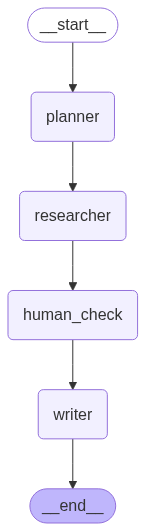

In [15]:
from IPython.display import Image
from IPython.display import display

display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
# Example Run
query = {"input": "How can AI be used in agriculture, and what are the benefits and challenges?"}

In [17]:
final_state = graph.invoke(query)
print("\nFINAL OUTPUT:\n", final_state["final_output"])


PLAN CREATED:
 Of course. Here is a research plan broken down into three detailed steps to answer your question.

***

### **Research Plan: AI in Agriculture - Applications, Benefits, and Challenges**

**Objective:** To provide a comprehensive overview of how Artificial Intelligence is being applied in modern agriculture, detailing the resulting advantages and the significant hurdles to its widespread adoption.

---

### **Step 1: Identify and Detail the Core Applications of AI in Agriculture**

This initial step focuses on the "how" by cataloging the primary ways AI technology is being deployed across the agricultural value chain. The goal is to move beyond generalities and identify specific use cases and the technologies that enable them.

*   **Research Focus 1: Precision Agriculture and Crop Management.**
    *   Investigate how machine learning models analyze data from soil sensors, satellite imagery, and drones.
    *   Document AI's role in optimizing irrigation (smart irrigati